# Actividad 3.3 — Construcción del modelo de visión

**Maestría en Inteligencia Artificial · Visión Inteligente · Unidad III**
**Alumno:** David Díaz de la Cruz

---

## ¿Qué vamos a hacer?

Vamos a **construir y entrenar desde cero una red neuronal convolucional (CNN)** que mire una imagen
y diga qué figura geométrica contiene: **círculo**, **cuadrado** o **triángulo**.

El ejemplo es sencillo a propósito: así podemos concentrarnos en **cómo se construye, entrena y evalúa**
un modelo de visión, sin perdernos en detalles del problema.

### Las tres tareas de la actividad y dónde se resuelven

| Tarea pedida | Dónde se resuelve en este notebook |
|---|---|
| Seleccionar la arquitectura según el caso | Sección 1 y Sección 5 |
| Entrenar con el dataset propio | Secciones 2 a 9 (modelo base y modelo mejorado) |
| Registrar métricas de entrenamiento y validación | Secciones 7 a 10 (además se guardan en archivos CSV y JSON) |

## 1. ¿Qué arquitectura elegimos y por qué?

En visión por computadora, **el tipo de pregunta** que queremos responder decide la arquitectura:

| Pregunta | Tarea | Arquitectura típica | Salida |
|---|---|---|---|
| ¿**Qué** hay en la imagen? | Clasificación | **CNN** (LeNet, VGG, ResNet, MobileNet) | Una etiqueta por imagen |
| ¿Qué hay y **dónde** está? | Detección de objetos | **YOLO**, Faster R-CNN | Cajas + etiquetas |
| ¿A qué objeto pertenece **cada píxel**? | Segmentación | **U-Net**, Mask R-CNN | Una máscara del tamaño de la imagen |

Nuestro caso tiene **una sola figura por imagen** y solo queremos saber **cuál es**.
Eso es **clasificación**, así que la elección natural es una **CNN**.

Además, como el problema es sencillo (imágenes pequeñas de 64×64 en gris), basta una **CNN pequeña
entrenada desde cero**. No necesitamos una red preentrenada gigante como en la Actividad 2.3.

> **Idea clave:** una CNN aprende **filtros** (pequeñas ventanas de 3×3) que detectan patrones.
> Las primeras capas detectan bordes; las siguientes combinan bordes en esquinas y curvas;
> las últimas reconocen la figura completa.

## 2. Preparación: importar librerías

- **TensorFlow / Keras**: para construir y entrenar la red.
- **NumPy**: para manejar las imágenes como arreglos de números.
- **scikit-learn**: para dividir los datos y calcular métricas.
- **Matplotlib**: para hacer gráficas.

Fijamos una **semilla** para que los resultados se puedan repetir.

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Semilla: hace que los números "aleatorios" sean siempre los mismos -> resultados repetibles
SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

# Carpeta donde guardaremos figuras, métricas y el modelo
Path("resultados").mkdir(exist_ok=True)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

I0000 00:00:1793472735.480947    1649 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793472735.522374    1649 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793472736.794019    1649 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | Keras: 3.15.1


## 3. El dataset propio

Las imágenes las crea el script `generar_dataset.py` (incluido en la entrega).
Cada imagen tiene **una figura** con tamaño, posición, rotación, tono y grosor **aleatorios**, más un poco de ruido.
Así el modelo no puede "memorizar" una sola forma: tiene que aprender **qué hace que un triángulo sea triángulo**.

Las imágenes quedan en **una carpeta por clase**. Esta organización es la misma que se usa con datasets reales,
así que el mismo código sirve para otro problema con solo cambiar la carpeta.

In [2]:
CARPETA = Path("dataset_figuras")

# Si el dataset no existe todavía, lo generamos (400 imágenes por clase)
if not CARPETA.exists():
    os.system("python generar_dataset.py --por-clase 400")

# Las clases son los nombres de las carpetas, en orden alfabético
CLASES = sorted(p.name for p in CARPETA.iterdir() if p.is_dir())
print("Clases:", CLASES)

# Leemos todas las imágenes y guardamos su etiqueta (0, 1 o 2)
imagenes, etiquetas = [], []
for indice, clase in enumerate(CLASES):
    for archivo in sorted((CARPETA / clase).glob("*.png")):
        img = Image.open(archivo).convert("L")   # "L" = escala de grises
        imagenes.append(np.array(img))
        etiquetas.append(indice)

X = np.array(imagenes)    # forma: (número de imágenes, 64, 64)
y = np.array(etiquetas)   # forma: (número de imágenes,)

print("Imágenes cargadas:", X.shape)
print("Imágenes por clase:", {c: int((y == i).sum()) for i, c in enumerate(CLASES)})

   circulo: 400 imágenes en dataset_figuras/circulo
  cuadrado: 400 imágenes en dataset_figuras/cuadrado


 triangulo: 400 imágenes en dataset_figuras/triangulo
Listo. Total: 1200 imágenes.
Clases: ['circulo', 'cuadrado', 'triangulo']


Imágenes cargadas: (1200, 64, 64)
Imágenes por clase: {'circulo': 400, 'cuadrado': 400, 'triangulo': 400}


### 3.1 Veamos algunas imágenes

Siempre conviene **mirar los datos** antes de entrenar: así confirmamos que las etiquetas son correctas.

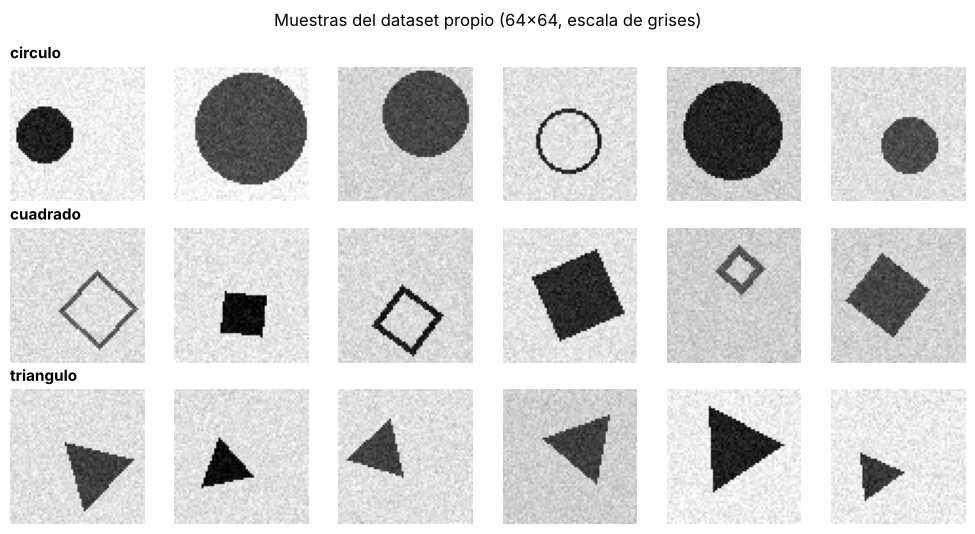

In [3]:
fig, ejes = plt.subplots(3, 6, figsize=(10, 5.4))
for fila, clase in enumerate(CLASES):
    indices = np.where(y == fila)[0][:6]          # primeras 6 imágenes de esa clase
    for col, i in enumerate(indices):
        ejes[fila, col].imshow(X[i], cmap="gray", vmin=0, vmax=255)
        ejes[fila, col].axis("off")
    ejes[fila, 0].set_title(clase, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Muestras del dataset propio (64×64, escala de grises)")
plt.tight_layout()
plt.savefig("resultados/01_muestras.png", dpi=150)
plt.show()

## 4. Dividir los datos: entrenamiento, validación y prueba

Separamos las imágenes en **tres grupos** que cumplen papeles distintos:

| Grupo | % | ¿Para qué sirve? | Analogía |
|---|---|---|---|
| **Entrenamiento** | 70 % | El modelo aprende con ellas | Ejercicios del libro |
| **Validación** | 15 % | Vigilamos el aprendizaje al final de cada época | Exámenes de práctica |
| **Prueba** | 15 % | Medición final honesta; el modelo **nunca** las ve al entrenar | Examen final |

Usamos `stratify=y` para que cada grupo tenga **la misma proporción** de círculos, cuadrados y triángulos.

In [4]:
# Primero separamos 70 % para entrenar y 30 % "restante"
X_train, X_resto, y_train, y_resto = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMILLA)

# El 30 % restante se parte a la mitad: 15 % validación y 15 % prueba
X_val, X_test, y_val, y_test = train_test_split(
    X_resto, y_resto, test_size=0.50, stratify=y_resto, random_state=SEMILLA)

print(f"Entrenamiento: {len(X_train)} imágenes")
print(f"Validación:    {len(X_val)} imágenes")
print(f"Prueba:        {len(X_test)} imágenes")

Entrenamiento: 840 imágenes
Validación:    180 imágenes
Prueba:        180 imágenes


### 4.1 Preprocesamiento: normalizar y agregar el canal

1. **Normalizar**: los píxeles van de 0 a 255. Los dividimos entre 255 para dejarlos entre **0 y 1**.
   Las redes aprenden mejor con números pequeños.
2. **Agregar el canal**: Keras espera imágenes con forma `(alto, ancho, canales)`.
   Nuestras imágenes son grises (1 canal), así que pasamos de `(64, 64)` a `(64, 64, 1)`.

In [5]:
def preparar(imgs):
    imgs = imgs.astype("float32") / 255.0     # 0..255  ->  0..1
    return imgs[..., np.newaxis]              # (n, 64, 64) -> (n, 64, 64, 1)

X_train, X_val, X_test = preparar(X_train), preparar(X_val), preparar(X_test)
print("Forma de entrada a la red:", X_train.shape[1:])
print("Rango de valores:", X_train.min(), "a", X_train.max())

Forma de entrada a la red: (64, 64, 1)
Rango de valores: 0.0 a 1.0


## 5. Construir la CNN

Nuestra red tiene dos partes:

**A) Extractor de características** (3 bloques iguales):
- `Conv2D`: aplica varios **filtros de 3×3** que recorren la imagen buscando patrones (bordes, esquinas, curvas).
  Cada bloque usa el doble de filtros que el anterior: 16 → 32 → 64.
- `ReLU`: deja pasar los valores positivos y convierte en cero los negativos. Le da a la red capacidad de aprender relaciones "no lineales".
- `MaxPooling2D`: reduce la imagen a la mitad quedándose con el valor más alto de cada ventana de 2×2.
  Así la red se fija en **si** apareció un patrón, no en el píxel exacto donde apareció.

**B) Clasificador**:
- `Flatten`: "aplana" el resultado en un solo vector de números.
- `Dense(64)`: capa totalmente conectada que combina las características.
- `Dropout(0.3)`: durante el entrenamiento "apaga" al azar 30 % de las neuronas para evitar que memorice (sobreajuste).
- `Dense(3, softmax)`: da **3 probabilidades** que suman 1, una por clase.

```
Imagen 64×64×1 → [Conv 16 → Pool] → [Conv 32 → Pool] → [Conv 64 → Pool] → Flatten → Dense 64 → Dropout → Dense 3 (softmax)
                 64→32               32→16               16→8
```

La función tiene un parámetro `aumento` que por ahora dejamos en `False`. Lo usaremos en la Sección 9 para mejorar el modelo.

In [6]:
def crear_cnn(num_clases, aumento=False):
    capas = [keras.Input(shape=(64, 64, 1))]                         # imagen de entrada

    # (Opcional) Aumento de datos: se explica en la Sección 9.
    # Estas capas SOLO actúan durante el entrenamiento; al predecir no hacen nada.
    if aumento:
        capas += [
            layers.RandomFlip("horizontal_and_vertical"),  # espejo horizontal / vertical
            layers.RandomRotation(0.5),                    # gira hasta ±180°
            layers.RandomTranslation(0.1, 0.1),            # desplaza hasta 10 %
        ]

    capas += [
        # --- Bloque 1: detecta bordes y líneas sencillas ---
        layers.Conv2D(16, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),                            # 64x64 -> 32x32

        # --- Bloque 2: combina bordes en esquinas y curvas ---
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),                            # 32x32 -> 16x16

        # --- Bloque 3: reconoce partes más grandes de la figura ---
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),                            # 16x16 -> 8x8

        # --- Clasificador ---
        layers.Flatten(),                                            # 8x8x64 -> 4096 números
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),                                         # apaga 30 % al entrenar
        layers.Dense(num_clases, activation="softmax"),              # 3 probabilidades
    ]
    return keras.Sequential(capas, name="cnn_aumento" if aumento else "cnn_base")

modelo_base = crear_cnn(len(CLASES))
modelo_base.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 285,699 (1.09 MB)

 Trainable params: 285,699 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

**¿Cómo leer el resumen?**
- *Output Shape* muestra cómo la imagen se hace **más pequeña** (64 → 32 → 16 → 8) pero **más profunda** (1 → 16 → 32 → 64 canales).
- *Param #* son los **pesos** que la red aprenderá. Casi todos están en la capa `Dense(64)`, que conecta 4,096 entradas con 64 neuronas.

## 6. Compilar: elegir cómo aprende la red

Compilar es decirle a Keras tres cosas:

- **Función de pérdida** (`sparse_categorical_crossentropy`): mide **qué tan equivocada** está la red.
  Si la red da 90 % a la clase correcta, la pérdida es baja; si da 10 %, es alta.
  ("sparse" significa que nuestras etiquetas son números 0, 1, 2 y no vectores).
- **Optimizador** (`Adam`, tasa de aprendizaje 0.001): el algoritmo que **ajusta los pesos** para bajar la pérdida.
- **Métrica** (`accuracy` / exactitud): porcentaje de imágenes bien clasificadas. Es la que nosotros entendemos fácilmente.

In [7]:
def compilar(modelo):
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

compilar(modelo_base)

## 7. Entrenar y registrar las métricas

Conceptos básicos:
- **Época**: una pasada completa por todas las imágenes de entrenamiento.
- **Lote (batch)**: grupo de 32 imágenes que la red procesa antes de ajustar sus pesos.

Usamos tres **callbacks** (funciones que Keras llama al final de cada época):

| Callback | ¿Qué hace? |
|---|---|
| `CSVLogger` | **Registra** pérdida y exactitud de entrenamiento y validación en un archivo CSV |
| `ModelCheckpoint` | Guarda el modelo en disco cada vez que mejora la pérdida de validación |
| `EarlyStopping` | Detiene el entrenamiento si la validación deja de mejorar 8 épocas seguidas, y recupera los mejores pesos |

Como entrenaremos dos modelos, ponemos todo en una función `entrenar()` que podemos reutilizar.

In [8]:
def entrenar(modelo, nombre, epocas=60):
    # Entrena el modelo, guarda métricas en CSV y el mejor modelo en .keras
    callbacks = [
        keras.callbacks.CSVLogger(f"resultados/metricas_{nombre}.csv"),
        keras.callbacks.ModelCheckpoint(f"resultados/modelo_{nombre}.keras",
                                        monitor="val_loss", save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                      restore_best_weights=True),
    ]
    modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),   # al final de cada época se mide la validación
        epochs=epocas,                    # máximo (EarlyStopping puede parar antes)
        batch_size=32,
        callbacks=callbacks,
        verbose=2,                        # una línea por época
    )
    # Leemos el CSV y le ponemos nombres en español
    tabla = pd.read_csv(f"resultados/metricas_{nombre}.csv")
    tabla["epoch"] = tabla["epoch"] + 1   # numeramos las épocas desde 1
    tabla = tabla.rename(columns={
        "epoch": "época", "loss": "pérdida_entr", "accuracy": "exactitud_entr",
        "val_loss": "pérdida_val", "val_accuracy": "exactitud_val"})
    return tabla[["época", "pérdida_entr", "exactitud_entr", "pérdida_val", "exactitud_val"]]

metricas_base = entrenar(modelo_base, "base")

Epoch 1/60


27/27 - 2s - 93ms/step - accuracy: 0.3905 - loss: 1.0927 - val_accuracy: 0.5667 - val_loss: 1.0074


Epoch 2/60


27/27 - 2s - 73ms/step - accuracy: 0.5226 - loss: 0.9529 - val_accuracy: 0.5944 - val_loss: 0.8429


Epoch 3/60


27/27 - 1s - 46ms/step - accuracy: 0.6024 - loss: 0.8569 - val_accuracy: 0.6000 - val_loss: 0.8196


... (54 outputs left out)

Epoch 31/60


27/27 - 1s - 27ms/step - accuracy: 0.9774 - loss: 0.0609 - val_accuracy: 0.9111 - val_loss: 0.2816


Epoch 32/60


27/27 - 1s - 28ms/step - accuracy: 0.9857 - loss: 0.0465 - val_accuracy: 0.9389 - val_loss: 0.2761


### 7.1 Tabla de métricas por época (modelo base)

Es la misma información que quedó guardada en `resultados/metricas_base.csv`.

In [9]:
mejor_base = int(metricas_base["pérdida_val"].idxmin())
print(f"Épocas ejecutadas: {len(metricas_base)} | Mejor época (menor pérdida de validación): {mejor_base + 1}")
metricas_base.round(4)

Épocas ejecutadas: 32 | Mejor época (menor pérdida de validación): 24


,época,pérdida_entr,exactitud_entr,pérdida_val,exactitud_val
0,1,1.0927,0.3905,1.0074,0.5667
1,2,0.9529,0.5226,0.8429,0.5944
2,3,0.8569,0.6024,0.8196,0.6000
3,4,0.8159,0.6167,0.7758,0.6333
4,5,0.7439,0.6726,0.7404,0.6444
5,6,0.6890,0.6940,0.7138,0.6833
6,7,0.6336,0.7202,0.6490,0.6833
7,8,0.5368,0.7833,0.5923,0.6944
8,9,0.4712,0.7940,0.5363,0.7278
9,10,0.4211,0.8250,0.4962,0.7667


## 8. Curvas de aprendizaje: diagnosticar el modelo

Las curvas nos dicen **cómo aprendió** la red:

- Si **ambas** pérdidas bajan juntas → la red aprende algo que **generaliza**. ✅
- Si la de entrenamiento sigue bajando pero la de validación **se estanca o sube** → **sobreajuste** (la red memoriza). ⚠️
- Si **ninguna** baja → la red no aprende (modelo muy simple, tasa de aprendizaje mala, etc.). ❌

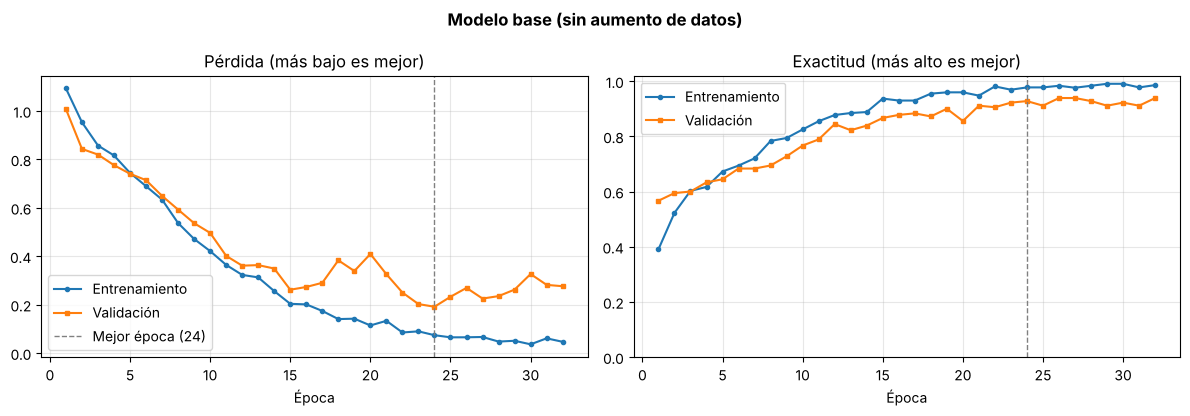

Última época -> exactitud entrenamiento: 98.57% | exactitud validación: 93.89% | brecha: 4.68%


In [10]:
def graficar_curvas(tabla, titulo, archivo):
    mejor = int(tabla["pérdida_val"].idxmin()) + 1
    ep = tabla["época"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))

    a1.plot(ep, tabla["pérdida_entr"], "o-", ms=3, label="Entrenamiento")
    a1.plot(ep, tabla["pérdida_val"], "s-", ms=3, label="Validación")
    a1.axvline(mejor, color="gray", ls="--", lw=1, label=f"Mejor época ({mejor})")
    a1.set_title("Pérdida (más bajo es mejor)"); a1.set_xlabel("Época"); a1.legend(); a1.grid(alpha=.3)

    a2.plot(ep, tabla["exactitud_entr"], "o-", ms=3, label="Entrenamiento")
    a2.plot(ep, tabla["exactitud_val"], "s-", ms=3, label="Validación")
    a2.axvline(mejor, color="gray", ls="--", lw=1)
    a2.set_title("Exactitud (más alto es mejor)"); a2.set_xlabel("Época"); a2.legend(); a2.grid(alpha=.3)
    a2.set_ylim(0, 1.02)

    plt.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.savefig(archivo, dpi=150)
    plt.show()

graficar_curvas(metricas_base, "Modelo base (sin aumento de datos)", "resultados/02_curvas_base.png")

ultima = metricas_base.iloc[-1]
print(f"Última época -> exactitud entrenamiento: {ultima['exactitud_entr']:.2%} | "
      f"exactitud validación: {ultima['exactitud_val']:.2%} | "
      f"brecha: {ultima['exactitud_entr'] - ultima['exactitud_val']:.2%}")

**Diagnóstico:** al principio las dos curvas mejoran juntas, pero después la pérdida de **entrenamiento sigue bajando**
mientras la de **validación se estanca y sube**. Se abre una **brecha** entre ambas: el modelo empieza a **memorizar**
las 840 imágenes de entrenamiento en lugar de aprender la forma general de cada figura. Es **sobreajuste**.

¿Por qué pasa? Tenemos pocas imágenes (280 por clase) y muchos parámetros (≈ 286 mil).

## 9. Mejora: aumento de datos (*data augmentation*)

Si el problema es que hay **pocas imágenes**, una solución barata es **inventar variaciones** de las que ya tenemos.
Un triángulo girado 90° **sigue siendo un triángulo**; un cuadrado reflejado en espejo **sigue siendo un cuadrado**.

Las capas de aumento de datos transforman cada imagen **al azar en cada época**, así que la red casi nunca ve
dos veces exactamente la misma imagen:

| Capa | Transformación |
|---|---|
| `RandomFlip` | Espejo horizontal y/o vertical |
| `RandomRotation(0.5)` | Rotación aleatoria de hasta ±180° |
| `RandomTranslation(0.1, 0.1)` | Desplazamiento de hasta 10 % |

> ⚠️ **Ojo:** el aumento debe **respetar la etiqueta**. Para figuras, girar es válido. Para dígitos no:
> un 6 girado 180° parece un 9.

Primero veamos qué produce el aumento sobre **una misma imagen**:

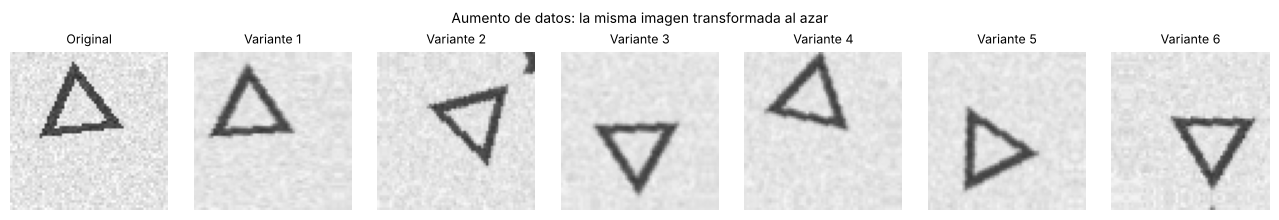

In [11]:
aumentador = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5),
    layers.RandomTranslation(0.1, 0.1),
])

original = X_train[np.where(y_train == CLASES.index("triangulo"))[0][0]]
fig, ejes = plt.subplots(1, 7, figsize=(13, 2.2))
ejes[0].imshow(original[:, :, 0], cmap="gray", vmin=0, vmax=1); ejes[0].set_title("Original", fontsize=9)
for k in range(1, 7):
    variante = aumentador(original[np.newaxis], training=True)[0]   # training=True activa el aumento
    ejes[k].imshow(np.array(variante)[:, :, 0], cmap="gray", vmin=0, vmax=1)
    ejes[k].set_title(f"Variante {k}", fontsize=9)
for e in ejes: e.axis("off")
plt.suptitle("Aumento de datos: la misma imagen transformada al azar", fontsize=10)
plt.tight_layout()
plt.savefig("resultados/03_aumento_datos.png", dpi=150)
plt.show()

**Dos detalles que se ven en la imagen (y que conviene saber):**
1. Las variantes se ven **más suaves** que la original: al girar, Keras interpola los píxeles y eso **difumina el ruido**.
2. En la variante 2 aparece un pedazo de figura en la esquina: al girar, los huecos se rellenan **reflejando** la imagen
   (`fill_mode="reflect"`, el valor por defecto). Es un pequeño artefacto que la red debe aprender a ignorar.

Ahora entrenamos **la misma CNN** (misma arquitectura, mismos parámetros, mismos datos), solo que **con aumento de datos**.
Así cualquier diferencia en los resultados se debe únicamente al aumento.
Este segundo modelo se guarda como `resultados/modelo_aumento.keras`.

In [12]:
modelo_aum = crear_cnn(len(CLASES), aumento=True)
compilar(modelo_aum)
print("Parámetros modelo base:     ", modelo_base.count_params())
print("Parámetros modelo aumentado:", modelo_aum.count_params(), "(las capas de aumento no tienen pesos)")

metricas_aum = entrenar(modelo_aum, "aumento")
mejor_aum = int(metricas_aum["pérdida_val"].idxmin())
print(f"\nÉpocas ejecutadas: {len(metricas_aum)} | Mejor época: {mejor_aum + 1}")

Parámetros modelo base:      285699
Parámetros modelo aumentado: 285699 (las capas de aumento no tienen pesos)
Epoch 1/60


27/27 - 3s - 100ms/step - accuracy: 0.3988 - loss: 1.0886 - val_accuracy: 0.5278 - val_loss: 0.9825


Epoch 2/60


27/27 - 1s - 44ms/step - accuracy: 0.4690 - loss: 1.0117 - val_accuracy: 0.5222 - val_loss: 0.8759


Epoch 3/60


27/27 - 1s - 44ms/step - accuracy: 0.5119 - loss: 0.9661 - val_accuracy: 0.5556 - val_loss: 0.8948


... (111 outputs left out)

27/27 - 1s - 42ms/step - accuracy: 0.9762 - loss: 0.0941 - val_accuracy: 1.0000 - val_loss: 0.0167


Epoch 60/60


27/27 - 1s - 35ms/step - accuracy: 0.9726 - loss: 0.0819 - val_accuracy: 1.0000 - val_loss: 0.0131



Épocas ejecutadas: 60 | Mejor época: 60


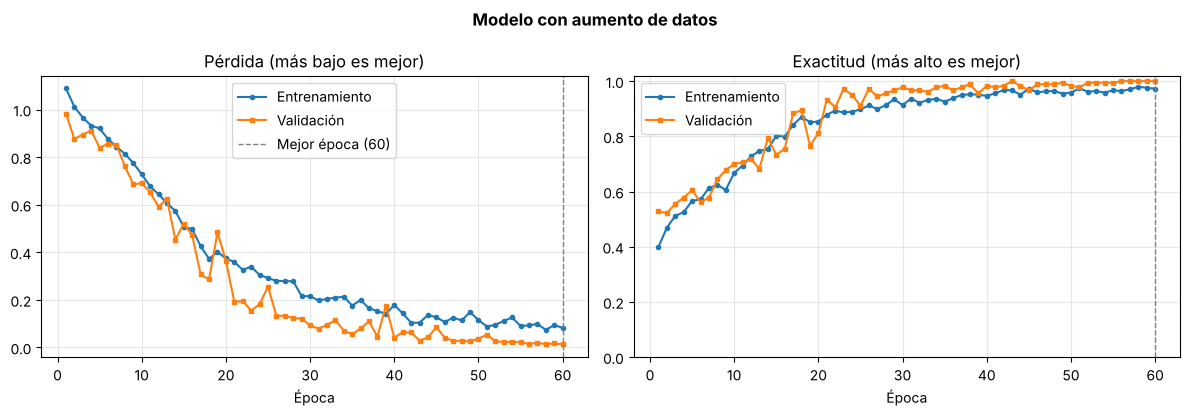

,época,pérdida_entr,exactitud_entr,pérdida_val,exactitud_val
50,51,0.0880,0.9738,0.0536,0.9778
51,52,0.0952,0.9619,0.0262,0.9944
52,53,0.1112,0.9643,0.0229,0.9944
53,54,0.1260,0.9583,0.0231,0.9944
54,55,0.0899,0.9667,0.0217,0.9944
55,56,0.0932,0.9643,0.0146,1.0000
56,57,0.0989,0.9702,0.0190,1.0000
57,58,0.0738,0.9798,0.0142,1.0000
58,59,0.0941,0.9762,0.0167,1.0000
59,60,0.0819,0.9726,0.0131,1.0000


In [13]:
graficar_curvas(metricas_aum, "Modelo con aumento de datos", "resultados/04_curvas_aumento.png")
metricas_aum.round(4).tail(10)   # últimas 10 épocas registradas

**Observa la diferencia:** con aumento de datos las curvas de entrenamiento y validación **avanzan juntas** y la
validación incluso queda **por encima** del entrenamiento en varias épocas. Esto es normal: al entrenar, la red ve imágenes
transformadas (más difíciles) y además tiene Dropout activo; al validar ve las imágenes originales y sin Dropout.
El modelo **ya no memoriza**: necesita más épocas, pero aprende la forma general de cada figura.

**Otro detalle:** en este modelo la mejor época coincide con la **última permitida** (60).
Eso indica que el modelo **todavía podía mejorar** un poco con más épocas; con aumento de datos el aprendizaje es más lento pero más sano.

## 10. Evaluación final con el conjunto de prueba

Ahora sí usamos las imágenes de **prueba**, que ningún modelo vio durante el entrenamiento.
Calculamos:

- **Exactitud**: % de aciertos totales.
- **Precisión** de una clase: de todas las veces que el modelo dijo "triángulo", ¿cuántas eran triángulo?
- **Recall (sensibilidad)**: de todos los triángulos reales, ¿cuántos encontró?
- **F1**: promedio equilibrado entre precisión y recall.
- **Matriz de confusión**: tabla que muestra **con qué se confunde** cada clase.

In [14]:
comparacion = []
for nombre, modelo, tabla in [("Base", modelo_base, metricas_base),
                              ("Con aumento", modelo_aum, metricas_aum)]:
    perdida, exactitud = modelo.evaluate(X_test, y_test, verbose=0)
    m = tabla.iloc[int(tabla["pérdida_val"].idxmin())]   # métricas de la mejor época
    comparacion.append({
        "modelo": nombre,
        "épocas": len(tabla),
        "mejor_época": int(m["época"]),
        "exactitud_entr": m["exactitud_entr"], "exactitud_val": m["exactitud_val"],
        "pérdida_val": m["pérdida_val"],
        "exactitud_prueba": exactitud, "pérdida_prueba": perdida,
    })
comparacion = pd.DataFrame(comparacion)
comparacion.round(4)

,modelo,épocas,mejor_época,exactitud_entr,exactitud_val,pérdida_val,exactitud_prueba,pérdida_prueba
0,Base,32,24,0.9774,0.9278,0.1914,0.8944,0.3825
1,Con aumento,60,60,0.9726,1.0000,0.0131,0.9944,0.0314


El modelo con aumento de datos es el **modelo final** del proyecto. Veamos su detalle por clase:

In [15]:
modelo = modelo_aum                                   # modelo final
probabilidades = modelo.predict(X_test, verbose=0)    # 3 probabilidades por imagen
y_pred = probabilidades.argmax(axis=1)                # nos quedamos con la más alta
y_pred_base = modelo_base.predict(X_test, verbose=0).argmax(axis=1)

print(classification_report(y_test, y_pred, target_names=CLASES, digits=4))

              precision    recall  f1-score   support

     circulo     1.0000    1.0000    1.0000        60
    cuadrado     1.0000    0.9833    0.9916        60
   triangulo     0.9836    1.0000    0.9917        60

    accuracy                         0.9944       180
   macro avg     0.9945    0.9944    0.9944       180
weighted avg     0.9945    0.9944    0.9944       180



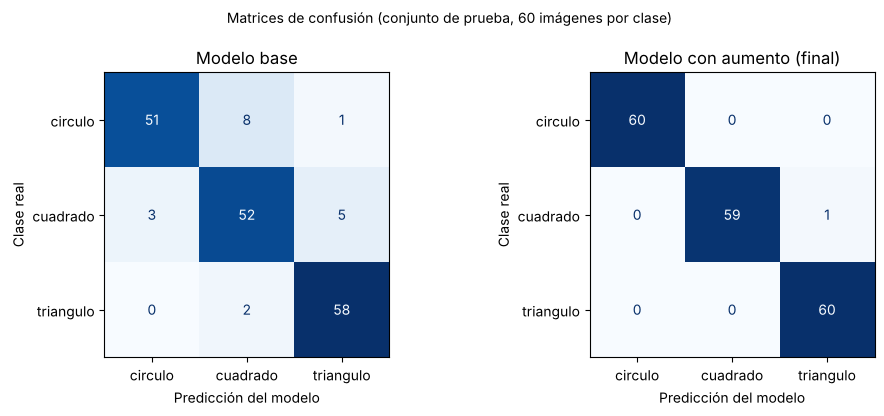

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
for eje, pred, titulo in [(a1, y_pred_base, "Modelo base"), (a2, y_pred, "Modelo con aumento (final)")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASES).plot(
        ax=eje, cmap="Blues", colorbar=False)
    eje.set_title(titulo); eje.set_xlabel("Predicción del modelo"); eje.set_ylabel("Clase real")
plt.suptitle("Matrices de confusión (conjunto de prueba, 60 imágenes por clase)", fontsize=10)
plt.tight_layout()
plt.savefig("resultados/05_matrices_confusion.png", dpi=150)
plt.show()

### 10.1 Guardar el resumen de métricas

Guardamos todo en `resultados/metricas_finales.json` para el reporte de avance.

In [17]:
def resumen_modelo(tabla, pred, fila_comp):
    rep = classification_report(y_test, pred, target_names=CLASES, output_dict=True)
    mejor = tabla.iloc[int(tabla["pérdida_val"].idxmin())]
    ultima = tabla.iloc[-1]
    cols = ["pérdida_entr", "exactitud_entr", "pérdida_val", "exactitud_val"]
    return {
        "epocas_ejecutadas": int(len(tabla)),
        "mejor_epoca": int(mejor["época"]),
        "mejor_epoca_metricas": {k: round(float(mejor[k]), 4) for k in cols},
        "ultima_epoca_metricas": {k: round(float(ultima[k]), 4) for k in cols},
        "prueba": {"perdida": round(float(fila_comp["pérdida_prueba"]), 4),
                   "exactitud": round(float(fila_comp["exactitud_prueba"]), 4)},
        "por_clase": {c: {m: round(rep[c][m], 4) for m in ["precision", "recall", "f1-score"]}
                      for c in CLASES},
        "macro_f1": round(rep["macro avg"]["f1-score"], 4),
        "matriz_confusion": confusion_matrix(y_test, pred).tolist(),
    }

resumen = {
    "clases": CLASES,
    "imagenes": {"entrenamiento": len(X_train), "validacion": len(X_val), "prueba": len(X_test)},
    "parametros": int(modelo.count_params()),
    "base": resumen_modelo(metricas_base, y_pred_base, comparacion.iloc[0]),
    "aumento": resumen_modelo(metricas_aum, y_pred, comparacion.iloc[1]),
}
with open("resultados/metricas_finales.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)
print(json.dumps(resumen, ensure_ascii=False, indent=2))

{
  "clases": [
    "circulo",
    "cuadrado",
    "triangulo"
  ],
  "imagenes": {
    "entrenamiento": 840,
    "validacion": 180,
    "prueba": 180
  },
  "parametros": 285699,
  "base": {
    "epocas_ejecutadas": 32,
    "mejor_epoca": 24,
    "mejor_epoca_metricas": {
      "pérdida_entr": 0.0739,
      "exactitud_entr": 0.9774,
      "pérdida_val": 0.1914,
      "exactitud_val": 0.9278
    },
    "ultima_epoca_metricas": {
      "pérdida_entr": 0.0465,
      "exactitud_entr": 0.9857,
      "pérdida_val": 0.2761,
      "exactitud_val": 0.9389
    },
    "prueba": {
      "perdida": 0.3825,
      "exactitud": 0.8944
    },
    "por_clase": {
      "circulo": {
        "precision": 0.9444,
        "recall": 0.85,
        "f1-score": 0.8947
      },
      "cuadrado": {
        "precision": 0.8387,
        "recall": 0.8667,
        "f1-score": 0.8525
      },
      "triangulo": {
        "precision": 0.9062,
        "recall": 0.9667,
        "f1-score": 0.9355
      }
    },
    "macr

## 11. ¿En qué se equivoca el modelo final?

Ver los errores es la mejor manera de **entender las limitaciones** del modelo.
Mostramos las imágenes de prueba mal clasificadas y, si hay pocas, completamos con las predicciones **menos seguras**
(aquellas donde la probabilidad más alta fue menor).

Imágenes mal clasificadas: 1 de 180


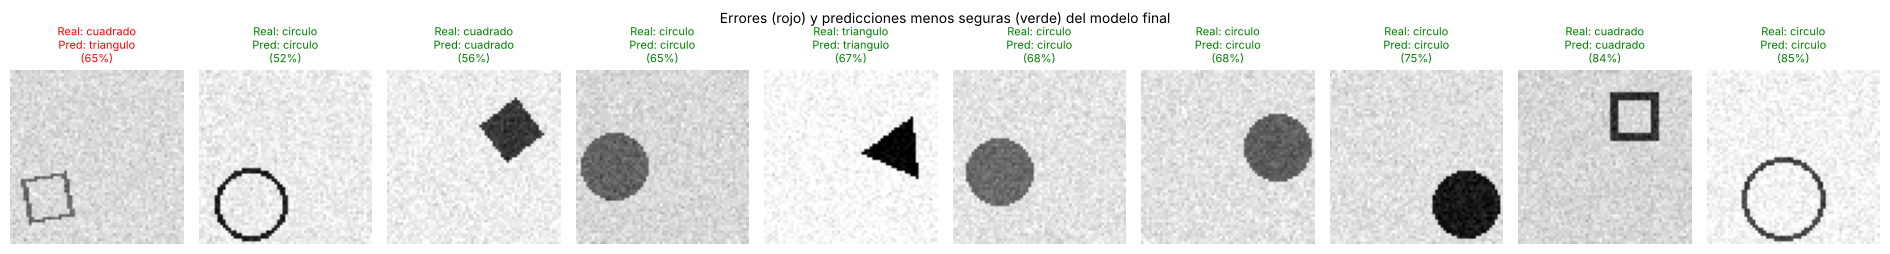

In [18]:
errores = np.where(y_pred != y_test)[0]
print(f"Imágenes mal clasificadas: {len(errores)} de {len(y_test)}")

confianza = probabilidades.max(axis=1)                    # probabilidad de la clase elegida
dudosas = [i for i in np.argsort(confianza) if i not in errores]
mostrar = (list(errores) + dudosas)[:10]

fig, ejes = plt.subplots(1, len(mostrar), figsize=(1.9 * len(mostrar), 2.7))
for eje, i in zip(ejes, mostrar):
    eje.imshow(X_test[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    color = "red" if y_pred[i] != y_test[i] else "green"
    eje.set_title(f"Real: {CLASES[y_test[i]]}\nPred: {CLASES[y_pred[i]]}\n({confianza[i]:.0%})",
                  fontsize=8, color=color)
    eje.axis("off")
plt.suptitle("Errores (rojo) y predicciones menos seguras (verde) del modelo final", fontsize=10)
plt.tight_layout()
plt.savefig("resultados/06_errores_y_dudas.png", dpi=150)
plt.show()

## 12. ¿Qué "ve" la red? Mapas de características

Una forma didáctica de abrir la "caja negra" es mirar la salida de la **primera capa convolucional**.
Cada uno de sus 16 filtros produce una imagen nueva (**mapa de características**).
Varios filtros resaltan **bordes** con distintas orientaciones o separan la figura del fondo:
justo la información que se necesita para distinguir lados rectos (cuadrado, triángulo) de bordes curvos (círculo).

/usr/local/lib/python3.13/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_15']
Received: inputs=Tensor(shape=(1, 64, 64, 1))
  warnings.warn(msg)


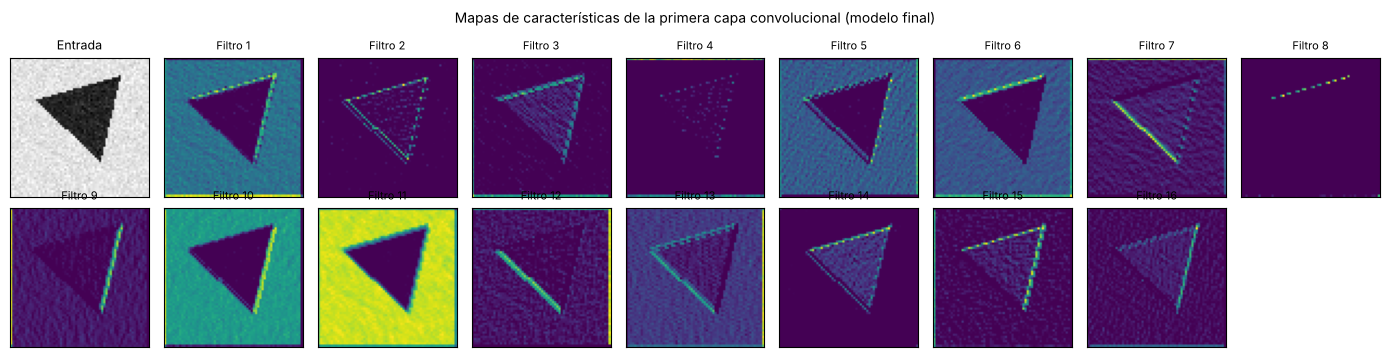

In [19]:
# Buscamos la primera capa Conv2D del modelo final (después de las capas de aumento)
primera_conv = [c for c in modelo.layers if isinstance(c, layers.Conv2D)][0]
extractor = keras.Model(inputs=modelo.inputs, outputs=primera_conv.output)

ejemplo = X_test[np.where(y_test == CLASES.index("triangulo"))[0][0]]
mapas = np.array(extractor(ejemplo[np.newaxis], training=False))[0]   # forma (64, 64, 16)

fig, ejes = plt.subplots(2, 9, figsize=(14, 3.6))
ejes = ejes.ravel()
ejes[0].imshow(ejemplo[:, :, 0], cmap="gray"); ejes[0].set_title("Entrada", fontsize=9)
for k in range(16):
    ejes[k + 1].imshow(mapas[:, :, k], cmap="viridis")
    ejes[k + 1].set_title(f"Filtro {k + 1}", fontsize=8)
ejes[17].axis("off")
for e in ejes: e.set_xticks([]); e.set_yticks([])
plt.suptitle("Mapas de características de la primera capa convolucional (modelo final)", fontsize=10)
plt.tight_layout()
plt.savefig("resultados/07_mapas_caracteristicas.png", dpi=150)
plt.show()

## 13. Usar el modelo guardado con imágenes nuevas

El **modelo entrenado** quedó guardado en `resultados/modelo_aumento.keras` (es el entregable principal).
Para comprobar que funciona, lo cargamos desde el archivo y clasificamos **figuras recién generadas**,
que no forman parte de ningún grupo anterior.

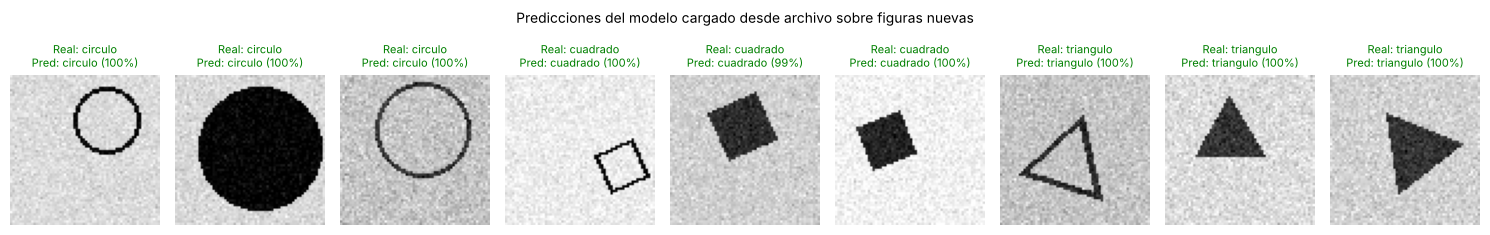

In [20]:
import random
from generar_dataset import dibujar_figura   # reutilizamos la función que dibuja figuras

modelo_cargado = keras.models.load_model("resultados/modelo_aumento.keras")

random.seed(7); np.random.seed(7)   # otra semilla -> figuras nuevas
nuevas = [(c, dibujar_figura(c)) for c in CLASES for _ in range(3)]

fig, ejes = plt.subplots(1, len(nuevas), figsize=(15, 2.6))
for eje, (real, img) in zip(ejes, nuevas):
    entrada = preparar(np.array(img)[np.newaxis])           # misma preparación que al entrenar
    prob = modelo_cargado.predict(entrada, verbose=0)[0]
    pred = CLASES[prob.argmax()]
    eje.imshow(img, cmap="gray"); eje.axis("off")
    eje.set_title(f"Real: {real}\nPred: {pred} ({prob.max():.0%})", fontsize=8,
                  color="green" if pred == real else "red")
plt.suptitle("Predicciones del modelo cargado desde archivo sobre figuras nuevas", fontsize=10)
plt.tight_layout()
plt.savefig("resultados/08_prediccion_nuevas.png", dpi=150)
plt.show()

## 14. Resumen

- Se eligió una **CNN** porque el caso es de **clasificación** (una etiqueta por imagen). YOLO y U-Net resuelven detección y segmentación.
- Se entrenaron dos versiones de la misma red con el **dataset propio**:
  1. **Modelo base**: aprende rápido pero **sobreajusta** (la validación se separa del entrenamiento).
  2. **Modelo con aumento de datos**: misma arquitectura y mismos parámetros, pero con giros, reflejos y desplazamientos aleatorios.
     Generaliza mejor y es el **modelo final**.
- Las métricas de entrenamiento y validación quedaron **registradas época por época** en
  `resultados/metricas_base.csv` y `resultados/metricas_aumento.csv`, y el resumen final en `resultados/metricas_finales.json`.
- El modelo entrenado quedó en `resultados/modelo_aumento.keras` y se puede volver a cargar para clasificar imágenes nuevas.

**Para usar otro dataset** (por ejemplo, el del proyecto integrador): basta con poner las imágenes en
una carpeta por clase y cambiar la variable `CARPETA`. Si las imágenes son a color, se cambia `convert("L")`
por `convert("RGB")` y la entrada de la red a `(64, 64, 3)`. Y hay que revisar que el aumento de datos
**respete las etiquetas** de ese nuevo problema.